In [3]:
# Jika library belum terpasang, jalankan sekali:
# %pip install -q torch torchvision numpy pandas matplotlib "torchmetrics[image]" torch-fidelity

from pathlib import Path
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import ConcatDataset, Subset, DataLoader
from torchvision import datasets, transforms

SEED, BATCH, LATENT, EPOCHS = 42, 128, 64, 15
LR, FID_SAMPLES = 2e-4, 2048  # sama: FID-2048 / 2048 gambar seperti VAE
RESUME = False  # True untuk melanjutkan training dari checkpoint terakhir
OUT = Path('outputs/vanilla_gan')
OUT.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = Path('fashion_mnist_split_seed42.npz')
CHECKPOINT = OUT / 'gan_last.pt'

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [4]:
full = ConcatDataset([
    datasets.FashionMNIST('data', train=True, download=True, transform=transforms.ToTensor()),
    datasets.FashionMNIST('data', train=False, download=True, transform=transforms.ToTensor()),
])
if SPLIT_FILE.exists():
    with np.load(SPLIT_FILE) as s:
        train_idx, val_idx, test_idx = s['train_idx'], s['val_idx'], s['test_idx']
else:
    idx = torch.randperm(len(full), generator=torch.Generator().manual_seed(SEED)).numpy()
    train_idx, val_idx, test_idx = idx[:56000], idx[56000:63000], idx[63000:]
    np.savez_compressed(SPLIT_FILE, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)

assert (len(train_idx), len(val_idx), len(test_idx)) == (56000, 7000, 7000)
assert len(np.unique(np.r_[train_idx, val_idx, test_idx])) == len(full)
train_set, val_set, test_set = [Subset(full, a.tolist()) for a in (train_idx, val_idx, test_idx)]
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_set, batch_size=BATCH, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False)
print('Train / Val / Test:', len(train_set), len(val_set), len(test_set))

100%|██████████| 26.4M/26.4M [00:01<00:00, 21.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 305kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.57MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.1MB/s]


Train / Val / Test: 56000 7000 7000


In [5]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(LATENT, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid()
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1)  # logits, tanpa Sigmoid
        )

    def forward(self, x):
        return self.net(x)

G, D = Generator().to(device), Discriminator().to(device)
opt_g = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))
loss_fn = nn.BCEWithLogitsLoss()
print('Generator params:', sum(p.numel() for p in G.parameters()))
print('Discriminator params:', sum(p.numel() for p in D.parameters()))

Generator params: 550416
Discriminator params: 533505


In [6]:
def sync():
    if device.type == 'cuda': torch.cuda.synchronize()
    elif device.type == 'mps': torch.mps.synchronize()

def run_epoch(loader, training):
    G.train(training); D.train(training)
    d_sum = g_sum = count = 0
    with torch.set_grad_enabled(training):
        for real, _ in loader:
            real = real.to(device)
            n = len(real)
            z = torch.randn(n, LATENT, device=device)
            fake = G(z)

            # (1) D: membedakan gambar asli (1) dan palsu (0)
            if training: opt_d.zero_grad()
            d_loss = (loss_fn(D(real), torch.ones(n, 1, device=device)) +
                      loss_fn(D(fake.detach()), torch.zeros(n, 1, device=device))) / 2
            if training:
                d_loss.backward()
                opt_d.step()

            # (2) G: menipu D; bobot D dibekukan saat update G
            if training:
                opt_g.zero_grad()
                for p in D.parameters(): p.requires_grad_(False)
            g_loss = loss_fn(D(fake), torch.ones(n, 1, device=device))
            if training:
                g_loss.backward()
                opt_g.step()
                for p in D.parameters(): p.requires_grad_(True)

            d_sum += d_loss.item() * n
            g_sum += g_loss.item() * n
            count += n
    return d_sum / count, g_sum / count

history, start_epoch = [], 1
if RESUME and CHECKPOINT.exists():
    saved = torch.load(CHECKPOINT, map_location=device, weights_only=False)  # hanya checkpoint sendiri
    G.load_state_dict(saved['G']); D.load_state_dict(saved['D'])
    opt_g.load_state_dict(saved['opt_g']); opt_d.load_state_dict(saved['opt_d'])
    history, start_epoch = saved['history'], saved['epoch'] + 1
    print('Resuming from epoch', start_epoch)

for epoch in range(start_epoch, EPOCHS + 1):
    sync(); start = time.perf_counter()
    train_d, train_g = run_epoch(train_loader, training=True)
    sync(); seconds = time.perf_counter() - start
    val_d, val_g = run_epoch(val_loader, training=False)
    history.append({'epoch': epoch, 'train_d_loss': train_d, 'train_g_loss': train_g,
                    'val_d_loss': val_d, 'val_g_loss': val_g, 'training_time_s': seconds})
    torch.save({'epoch': epoch, 'G': G.state_dict(), 'D': D.state_dict(),
                'opt_g': opt_g.state_dict(), 'opt_d': opt_d.state_dict(),
                'history': history}, CHECKPOINT)
    print(f'Epoch {epoch:02} | D={train_d:.4f} G={train_g:.4f}'
          f' | Val D={val_d:.4f} G={val_g:.4f} | {seconds:.1f}s')

if not history:
    raise RuntimeError('Belum ada hasil training; jalankan EPOCHS >= 1.')
history_df = pd.DataFrame(history)
history_df.to_csv(OUT / 'vanilla_gan_history.csv', index=False)
G.eval(); D.eval()
torch.save(G.state_dict(), OUT / 'vanilla_gan_generator.pt')
print('Checkpoint epoch terakhir:', history_df.epoch.iloc[-1])

Epoch 01 | D=0.2632 G=2.5418 | Val D=0.2265 G=1.4033 | 8.3s
Epoch 02 | D=0.1945 G=3.4179 | Val D=0.1180 G=2.1042 | 7.0s
Epoch 03 | D=0.2869 G=2.7545 | Val D=0.2535 G=1.8161 | 8.4s
Epoch 04 | D=0.2850 G=2.6114 | Val D=0.2958 G=1.3762 | 8.0s
Epoch 05 | D=0.2972 G=2.4130 | Val D=0.2775 G=1.5521 | 7.1s
Epoch 06 | D=0.3049 G=2.4115 | Val D=0.5124 G=3.4472 | 7.8s
Epoch 07 | D=0.3482 G=2.0807 | Val D=0.3242 G=1.9449 | 7.4s
Epoch 08 | D=0.3114 G=2.1650 | Val D=0.2659 G=2.3177 | 7.1s
Epoch 09 | D=0.3590 G=2.1491 | Val D=0.3628 G=2.1081 | 7.9s
Epoch 10 | D=0.3644 G=1.9374 | Val D=0.3279 G=1.5512 | 8.4s
Epoch 11 | D=0.3900 G=1.9727 | Val D=0.3783 G=1.1743 | 7.1s
Epoch 12 | D=0.3791 G=1.9742 | Val D=0.4465 G=0.9790 | 8.7s
Epoch 13 | D=0.4197 G=1.8271 | Val D=0.3893 G=1.2623 | 7.6s
Epoch 14 | D=0.4287 G=1.7514 | Val D=0.4658 G=1.3667 | 7.1s
Epoch 15 | D=0.4367 G=1.6660 | Val D=0.4365 G=1.0441 | 7.8s
Checkpoint epoch terakhir: 15


In [7]:
z64 = torch.randn(64, LATENT, device=device)
with torch.inference_mode():
    for _ in range(10): G(z64)
    timings = []
    for _ in range(30):
        sync(); start = time.perf_counter()
        G(z64)
        sync(); timings.append((time.perf_counter() - start) * 1000)
latency = float(np.mean(timings))
print(f'Inference latency: {latency:.3f} ± {np.std(timings):.3f} ms / batch 64')

Inference latency: 0.200 ± 0.027 ms / batch 64


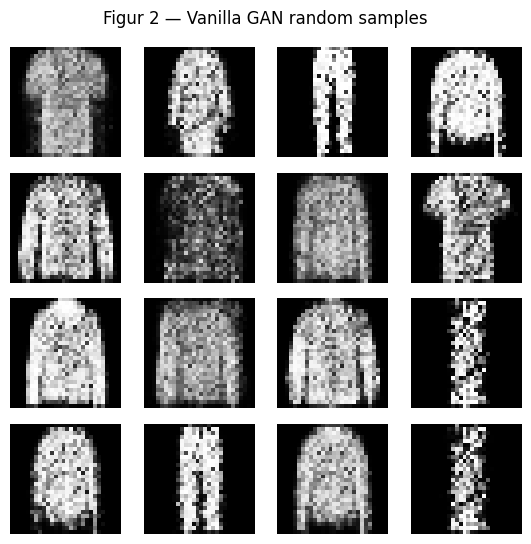

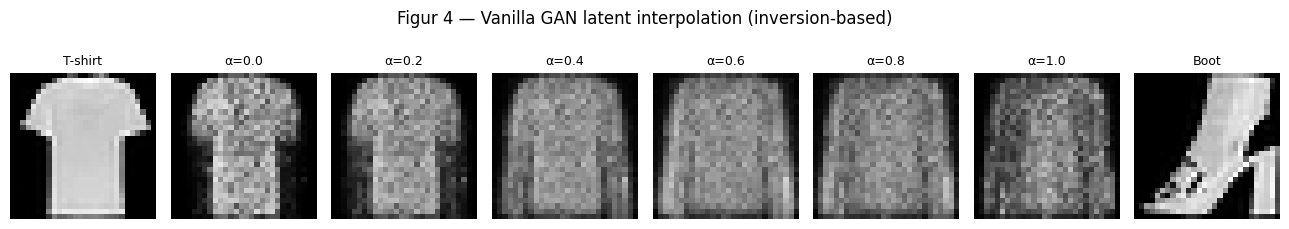

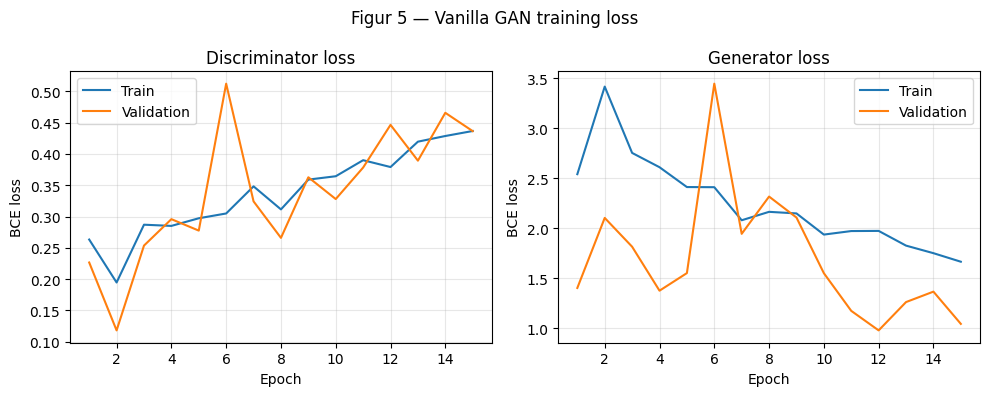

In [8]:
# Figur 2 — 16 gambar baru dari Gaussian noise
G.eval()
with torch.inference_mode():
    samples = G(torch.randn(16, LATENT, device=device)).cpu()
fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))
for ax, im in zip(axes.flat, samples):
    ax.imshow(im[0], cmap='gray', vmin=0, vmax=1); ax.axis('off')
fig.suptitle('Figur 2 — Vanilla GAN random samples')
plt.tight_layout(); plt.savefig(OUT / 'figure2_vanilla_gan_samples.png', dpi=200); plt.show()

# Figur 4 — Cari dua latent yang mendekati gambar kelas 0 dan 9 (GAN inversion)
def get_class_image(label):
    for img, y in test_set:
        if y == label: return img
    raise ValueError('Kelas tidak ada')

targets = torch.stack([get_class_image(0), get_class_image(9)]).to(device)
for p in G.parameters(): p.requires_grad_(False)
z_pair = nn.Parameter(torch.randn(2, LATENT, device=device))
z_optimizer = torch.optim.Adam([z_pair], lr=0.05)
for _ in range(200):
    z_optimizer.zero_grad()
    inversion_loss = F.mse_loss(G(z_pair), targets) + 0.001 * z_pair.square().mean()
    inversion_loss.backward()
    z_optimizer.step()
with torch.inference_mode():
    z_a, z_b = z_pair.detach()[0], z_pair.detach()[1]
    alphas = np.linspace(0, 1, 6)
    zz = torch.stack([(1 - float(a))*z_a + float(a)*z_b for a in alphas])
    interpolated = G(zz).cpu()
for p in G.parameters(): p.requires_grad_(True)

fig, axes = plt.subplots(1, 8, figsize=(13, 2.5))
for i, ax in enumerate(axes):
    im = targets[0,0].cpu() if i == 0 else targets[1,0].cpu() if i == 7 else interpolated[i-1,0]
    ax.imshow(im, cmap='gray', vmin=0, vmax=1)
    ax.set_title('T-shirt' if i == 0 else 'Boot' if i == 7 else f'α={alphas[i-1]:.1f}', fontsize=9)
    ax.axis('off')
fig.suptitle('Figur 4 — Vanilla GAN latent interpolation (inversion-based)')
plt.tight_layout(); plt.savefig(OUT / 'figure4_vanilla_gan_interpolation.png', dpi=200); plt.show()

# Figur 5 — Loss G dan D (nilai tidak harus monoton turun dalam GAN)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, k in zip(axes, ['d', 'g']):
    ax.plot(history_df.epoch, history_df[f'train_{k}_loss'], label='Train')
    ax.plot(history_df.epoch, history_df[f'val_{k}_loss'], label='Validation')
    ax.set(xlabel='Epoch', ylabel='BCE loss', title=f'{"Discriminator" if k == "d" else "Generator"} loss')
    ax.legend(); ax.grid(alpha=0.3)
fig.suptitle('Figur 5 — Vanilla GAN training loss')
plt.tight_layout(); plt.savefig(OUT / 'figure5_vanilla_gan_loss.png', dpi=200); plt.show()

## 7. FID — real test set vs generated (2048 masing-masing)

Metrik FID dari **Inception-2048** di `torchmetrics[image]`. Gambar grayscale 1 kanal diduplikasi menjadi RGB 3 kanal. Untuk kompatibilitas perangkat, FID dihitung di **CPU** jika menggunakan Mac MPS.

Jika ada error dependency, install: `%pip install -q "torchmetrics[image]" torch-fidelity` lalu jalankan kembali cell ini. Tidak ada nilai FID yang direkayasa.

In [10]:
%pip install -q "torchmetrics[image]" torch-fidelity

In [11]:
from torchmetrics.image.fid import FrechetInceptionDistance

fid_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
metric = FrechetInceptionDistance(feature=2048, normalize=True).to(fid_device)
metric.set_dtype(torch.float64)
fid_rng = torch.Generator().manual_seed(SEED + 123)

seen = 0
with torch.inference_mode():
    for real, _ in test_loader:
        if seen >= FID_SAMPLES: break
        real = real[:FID_SAMPLES - seen]
        z = torch.randn(len(real), LATENT, generator=fid_rng).to(device)
        fake = G(z).detach().to(fid_device)
        metric.update(real.to(fid_device).repeat(1, 3, 1, 1), real=True)
        metric.update(fake.repeat(1, 3, 1, 1), real=False)
        seen += len(real)
        if seen % 512 == 0: print('FID:', seen, '/', FID_SAMPLES)

fid_score = float(metric.compute().item())
print(f'FID-2048 ({seen} real + {seen} generated): {fid_score:.3f}')

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 218MB/s]


FID: 512 / 2048
FID: 1024 / 2048
FID: 1536 / 2048
FID: 2048 / 2048
FID-2048 (2048 real + 2048 generated): 205.635


In [12]:
result = pd.DataFrame([{
    'model': 'Vanilla GAN', 'dataset': 'Fashion-MNIST', 'seed': SEED,
    'train_size': len(train_set), 'val_size': len(val_set), 'test_size': len(test_set),
    'latent_dim': LATENT, 'batch_size': BATCH, 'epochs': int(history_df.epoch.iloc[-1]),
    'num_parameters': sum(p.numel() for p in G.parameters()) + sum(p.numel() for p in D.parameters()),
    'learning_rate': LR,
    'training_time_epoch_s_mean': history_df.training_time_s.mean(),
    'inference_latency_batch64_ms': latency,
    'test_mse': float('nan'), 'test_psnr_db': float('nan'), 'test_ssim': float('nan'),
    'fid': fid_score, 'fid_features': 2048, 'fid_samples': seen,
    'final_d_loss': float(history_df.train_d_loss.iloc[-1]),
    'final_g_loss': float(history_df.train_g_loss.iloc[-1]),
    'device': str(device),
}])
result.to_csv(OUT / 'vanilla_gan_metrics.csv', index=False)
print(result.T.to_string(header=False))
print('Seluruh hasil:', OUT.resolve())

vae_file = Path('outputs/vae/vae_metrics.csv')
if vae_file.exists():
    cols = ['model', 'fid', 'inference_latency_batch64_ms', 'training_time_epoch_s_mean']
    comparison = pd.concat([pd.read_csv(vae_file), result], ignore_index=True)
    comparison[cols].to_csv(OUT / 'vae_vs_vanilla_gan.csv', index=False)
    print('\nKomparasi VAE vs Vanilla GAN:')
    print(comparison[cols].to_string(index=False))

model                           Vanilla GAN
dataset                       Fashion-MNIST
seed                                     42
train_size                            56000
val_size                               7000
test_size                              7000
latent_dim                               64
batch_size                              128
epochs                                   15
num_parameters                      1083921
learning_rate                        0.0002
training_time_epoch_s_mean         7.713355
inference_latency_batch64_ms       0.200414
test_mse                                NaN
test_psnr_db                            NaN
test_ssim                               NaN
fid                              205.635444
fid_features                           2048
fid_samples                            2048
final_d_loss                       0.436735
final_g_loss                       1.665958
device                                 cuda
Seluruh hasil: /content/outputs/

In [13]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r "/content/outputs/vanilla_gan" "/content/drive/MyDrive/[CN] Colab Notebooks/[CV] Computer Vision/DCGANAE: All Experiments/Results"


Mounted at /content/drive
